# Search Results → AnnData

Converts raw DIANN output into [AnnData](https://anndata.readthedocs.io) objects for downstream analysis. This is the second step in the data-object creation pipeline (run after `01_metadata.ipynb`).

**Inputs**
- DIANN parquet files — contains DIANN search results for all samples but the Quantitative QC mixtures
- DIANN parquet files for the QCs — quantitative QC mixture runs (one per plate)
- `metadata.parquet` — sample-level annotations produced by `01_metadata.ipynb`

**Outputs** (written to `Data/AnnData_DIANN/`)
| File | Description |
|---|---|
| `adata_precursor.h5ad` | Precursor-level quantification, human samples |
| `adata_protein.h5ad` | Protein-level quantification, human samples |
| `adata_precursor_qc.h5ad` | Precursor-level quantification, QC mixtures |
| `adata_protein_qc.h5ad` | Protein-level quantification, QC mixtures |
| `search_results.parquet` | Filtered long-format search results, human samples |
| `search_results_qc.parquet` | Filtered long-format search results, QC mixtures |

---

## Imports

In [1]:
import os
from tqdm import tqdm
import pandas as pd
import numpy as np
from pathlib import Path
from glob import glob
import seaborn as sns
import matplotlib.pyplot as plt

# TODO: Fix ProteoBench dependency
from SCI_py.data.parse import df_to_anndata, align_obs_across_anndata
from SCI_py.data.read import load_spectronaut

tqdm.pandas()

## 0. Path Configuration

### Output paths

Resolved path relative to the notebook location. Override with the `SCI_DATA_DIR` environment variable when running outside the default directory structure or if the output data is stored elsewhere.

In [2]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT     = NOTEBOOK_DIR / "../../Data"
ROOT_OUT     = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

Output directory: /home/sam/SCI/SCI/Data


### Input paths

Points to the DIANN result files and the metadata parquet generated by the previous notebook. A warning is printed if the metadata file or any of the result files are missing, as the merge step will fail without it.

In [ ]:
# For the search result output from Spectronaut
ROOT_IN = '/public/conode53/sam/SCI_paper'

# RESULT_PATH = os.path.join(
#     ROOT_IN,
#     'DIANN_runs',
#     'Human',
#     'All',
#     'first_pass',
#     'cross_run'
# )


RESULT_PATH = glob(
    os.path.join(
        ROOT_IN,
        'DIANN_runs',
        'Human',
        '*',
        'first_pass', # Contains both MBR and first-pass results
        # Change path to switch between MBR and firstpass
        # 'report-first-pass.parquet'
        'report.parquet'
    )
)

# For the quantitative QCs run separately
QC_PATHS = glob(
    os.path.join(
        ROOT_IN,
        'QC_Quant',
        '*',
        'DIANN',
        '4',
        # Change path to switch between MBR and firstpass
        # 'report-first-pass.parquet'
        'report.parquet'
    )
)

# For the metadata file generated in previous notebook
METADATA_PATH = os.path.join(
    ROOT_OUT,
    'metadata',
    'metadata.parquet'
)
if not os.path.exists(METADATA_PATH):
    print("Warning: Run 01_metadata.ipynb first or change the METADATA_PATH variable.")
    
# if not os.path.exists(RESULT_PATH):
#     print("Warning: Edit result_path so it points to the correct location of the spectronaut results file.")
    
# for QC_PATH in QC_PATHS:
#     if not os.path.exists(QC_PATH):
#         print("Warning: Edit QC_PATHS so it points to the correct location of the Quant QC directory.")

In [4]:
from SCI_py.metadata.parse import FILENAME_CONVERTERS, get_institute

def load_diann(path):
    report = pd.read_parquet(path)
    report['plate_id'] = report['Run'].progress_apply(get_institute)
    report['sample_name'] = report.progress_apply(
        lambda x: FILENAME_CONVERTERS[x['plate_id']](x['Run']+'.RAW'),
        axis=1
    )
    report['sample_name'] = report['sample_name'].progress_apply(lambda x: x.lower())
    
    report['PrecursorIon'] = report.apply(
        lambda x: (
            str(x['Modified.Sequence'])
                .strip()
                .replace('(UniMod:1)', '[UNIMOD:1]-')
                .replace('(UniMod:4)', '[UNIMOD:4]')
                .replace('(UniMod:35)', '[UNIMOD:35]') + '/' + str(x['Precursor.Charge'])
        ),
        axis=1
    )
    
    report = report[
        (report['Global.Peptidoform.Q.Value'] < .01) &
        (report['Global.PG.Q.Value'] < .01) &
        (report['Protein.Q.Value'] < .01) &
        (report['Q.Value'] < .01)
    ]
    
    return report

## 1. Load Data

Parse DIANN reports and join them with sample metadata. The loading function standardises modification notation to UNIMOD format and constructs a canonical precursor ID (`FG.PrecursorIon`) used as the feature index at the precursor level.

### 1.1. Search Results

`load_spectronaut` reads the spectronaut results file and applies a couple of preprocessing steps:
1. **Institute / plate ID** — extracted from the raw filename via `get_institute`.
2. **Sample name** — converted to a canonical lowercase identifier using site-specific `FILENAME_CONVERTERS`.
3. **Modification notation** — Spectronaut labels (`[Oxidation (M)]`, etc.) are mapped to UNIMOD accessions for interoperability.

#### 1.1.1. Human samples (+ blanks)

Main SCI dataset: a single merged Spectronaut report covering all participating institutes. Blanks are retained at this stage and filtered downstream based on the `CellInBlank` metadata flag.

In [ ]:
# # For cross run paths
# report_SC = load_diann(
#     os.path.join(
#         RESULT_PATH,
#         'SingleCells',
#         'out',
#         'report.parquet'
#     )
# )
# report_QC = load_diann(
#     os.path.join(
#         RESULT_PATH,
#         'QC',
#         'out',
#         'report.parquet'
#     )
# )
# report_controls = load_diann(
#     os.path.join(
#         RESULT_PATH,
#         'Controls',
#         'out',
#         'report.parquet'
#     )
# )

# report = pd.concat([report_SC, report_QC, report_controls])

In [5]:
# For plate-by-plate results
report_list = []
for SC_PATH in tqdm(RESULT_PATH):
    sc = load_diann(SC_PATH)
    report_list.append(sc)
report = pd.concat(report_list, ignore_index=True)

100%|██████████| 9/9 [04:51<00:00, 32.43s/it]


In [6]:
report.shape

(14329943, 74)

#### 1.1.2. Quantitative QC (mixtures)

Each site ran a set of mixture-based QC samples independently (one Spectronaut export per site, stored under `QC_Quant/`). These are parsed with the same loader and concatenated into a single dataframe for joint analysis.

In [12]:
qc_list = []
for QC_PATH in tqdm(QC_PATHS):
    qc = load_diann(QC_PATH)
    qc_list.append(qc)
report_qc = pd.concat(qc_list, ignore_index=True)

100%|██████████| 9/9 [00:33<00:00,  3.75s/it]


### 1.2. Merge with Metadata

Join search results with sample-level metadata on `plate_id` + `sample_name`. This attaches morphological measurements (diameter, circularity, …), experimental annotations (gradient time, plate arrival), and quality flags (doublet, dying, …) to every quantified precursor row.

In [13]:
metadata = pd.read_parquet(
    METADATA_PATH
)

df = report.merge(metadata, on=['plate_id', 'sample_name'])
df_qc = report_qc.merge(metadata, on=['plate_id', 'sample_name'])

print(df.shape)
print(df_qc.shape)

(14329943, 150)
(310938, 150)


### 1.3. Subdivide Columns

Partition the merged dataframe columns into logical groups before pivoting to AnnData. This makes the mapping to AnnData slots explicit:

| Group | AnnData slot | Purpose |
|---|---|---|
| `cols_protpept_metadata` + `cols_idconf` + `cols_peptfeatures` | `adata.var` | Feature-level annotations |
| `cols_metadata` | `adata.obs` | Sample-level annotations |
| `cols_quant` | `adata.X` (via pivot) | Quantitative intensities |

Only the columns used downstream are retained, reducing memory footprint before the pivot.

In [14]:
# Identity / annotation columns (var-side metadata)
cols_protpept_metadata = [
    'Protein.Group',        # ~ PG.ProteinGroups
    'Protein.Ids',          # ~ PG.ProteinAccessions
    'Protein.Names',
    'Genes',
    'Stripped.Sequence',    # ~ PEP.StrippedSequence
    'Proteotypic',          # ~ PEP.IsProteotypic
    'Modified.Sequence',    # ~ EG.ModifiedSequence
    'PrecursorIon',
    'Precursor.Charge',     # ~ FG.Charge
    'Precursor.Id',         # ~ FG.PrecursorIon (precursor-level unique key)
    'Precursor.Mz',
    'Decoy',
]

# Confidence / Q-value columns
cols_idconf = [
    'Q.Value',                  # ~ FG.Qvalue (precursor-level run-specific)
    'Global.Q.Value',           # ~ EG.GlobalPrecursorQvalue
    'Lib.Q.Value',
    'PEP',
    'Peptidoform.Q.Value',
    'Global.Peptidoform.Q.Value',
    'PG.Q.Value',               # ~ PG.Qvalue
    'PG.PEP',
    'Global.PG.Q.Value',
    'Protein.Q.Value',
    'GG.Q.Value',
    'Channel.Q.Value',
    'Translated.Q.Value',
]

# Quantitative columns
cols_quant = [
    'Precursor.Quantity',       # ~ FG.Quantity / EG.TotalQuantity
    'Precursor.Normalised',
    'Ms1.Area',
    'Ms1.Normalised',
    'Ms1.Apex.Area',
    'PG.MaxLFQ',                # ~ PG.Quantity (the usual protein-level summary)
    'PG.TopN',
    'Genes.MaxLFQ',
    'Genes.MaxLFQ.Unique',
    'Genes.TopN',
    'Normalisation.Factor',
]

# Per-precursor feature columns (extraction / RT / IM / shape diagnostics)
cols_peptfeatures = [
    # Retention time
    'RT',                       # ~ EG.ApexRT
    'iRT',                      # ~ EG.iRTEmpirical
    'Predicted.RT',             # ~ EG.RTPredicted
    'Predicted.iRT',            # ~ EG.iRTPredicted
    'RT.Start',
    'RT.Stop',
    'FWHM',

    # Ion mobility (timsTOF)
    'IM',
    'iIM',
    'Predicted.IM',
    'Predicted.iIM',

    # MS1 / MS2 quality features
    'Ms1.Profile.Corr',
    'Ms1.Apex.Mz.Delta',
    'Ms1.Total.Signal.Before',
    'Ms1.Total.Signal.After',
    'Evidence',                 # closest analog to FG.CScore (DIA-NN's discriminant score)
    'Mass.Evidence',
    'Channel.Evidence',
    'Quantity.Quality',
    'Empirical.Quality',
    'Normalisation.Noise',
    'PG.MaxLFQ.Quality',
    'Genes.MaxLFQ.Quality',
    'Best.Fr.Mz',
    'Best.Fr.Mz.Delta',
]

cols_metadata = [
    'Run',
    'sample_name',
    'plate_id',
    'plate_idx',
    'source name',
    'comment[X position]',
    'comment[Y position]',
    'comment[Plate Number]',
    'comment[Gradient time]',
    'comment[thawing timepoint]',
    'comment[plate arrival]',
    'injection_order',
    'institute_name',
    'Reinjection',
    'Diameter',
    'Elongation',
    'Circularity',
    'Doublet',
    'Dividing',
    'Dying',
    'CellInBlank',
    'comment[plate arrival]_date',
    'comment[plate arrival]_time', 'comment[plate arrival]_datetime',
    'comment[Gradient time]_date', 'comment[Gradient time]_time',
    'comment[Gradient time]_datetime', 'instrument_type'
]

col_sample_index = ['sample_id']

var_cols = cols_protpept_metadata + cols_idconf + cols_peptfeatures

In [61]:
df = df.loc[
    :,
    (
        cols_protpept_metadata +
        col_sample_index +
        cols_idconf +
        cols_quant +
        cols_peptfeatures +
        cols_metadata
    )
]

df_qc = df_qc.loc[
    :,
    (
        cols_protpept_metadata +
        col_sample_index +
        cols_idconf +
        cols_quant +
        cols_peptfeatures +
        cols_metadata
    )
]

## 2. Create AnnData Objects

Pivot the long-format dataframes into AnnData's `obs × var` matrix layout. Precursor and protein objects are built separately because they use different feature indices (`FG.PrecursorIon` vs `PG.ProteinGroups`) and different quantification columns.

### 2.1. Parse Dataframe to AnnData

`df_to_anndata` pivots the long-format report into a sparse `obs × var` intensity matrix (`adata.X`). `align_obs_across_anndata` then ensures the precursor and protein objects share an identical observation index — required for any joint analysis or cross-level comparisons later. In other words, this makes it possible to apply a boolean sample filter, prepared with the precursor AnnData object to the protein Anndata object.

In [62]:
sample_col = 'sample_id'   # or 'Run'
var_cols = cols_protpept_metadata + cols_idconf + cols_peptfeatures

# Precursor-level AnnData
adata_precursor, X_precursor = df_to_anndata(
    df,
    feature_col = 'PrecursorIon',
    value_col   = 'Precursor.Quantity',
    sample_col  = sample_col,
    obs_cols    = cols_metadata,
    var_cols    = var_cols,
)

# Protein-group-level AnnData
adata_protein, X_protein = df_to_anndata(
    df,
    feature_col = 'Protein.Group',
    value_col   = 'PG.MaxLFQ',
    sample_col  = sample_col,
    obs_cols    = cols_metadata,
    var_cols    = ['Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes'],
)

# Layers for precursor AnnData
precursor_layers = [
    'Precursor.Normalised',
    'Ms1.Area',
    'Ms1.Normalised',
    'Ms1.Apex.Area',
    'Q.Value',
    'PEP',
    'Evidence',
    'Quantity.Quality',
    'Empirical.Quality',
    'Ms1.Profile.Corr',
    'RT',
    'IM',
    'FWHM',
]
for layer_info in tqdm(precursor_layers, desc='Adding layers to precursor AnnData...'):
    adata_layer, X_layer = df_to_anndata(
        df,
        feature_col = 'PrecursorIon',
        value_col   = layer_info,
        sample_col  = sample_col,
        obs_cols    = cols_metadata,
        var_cols    = var_cols,
    )
    adata_precursor, adata_layer = align_obs_across_anndata(
        adata_precursor, X_precursor, adata_layer, X_layer
    )
    adata_precursor.layers[layer_info] = adata_layer.X

# Layers for protein AnnData
protein_layers = [
    'PG.TopN',
    'PG.Q.Value',
    'PG.PEP',
    'Global.PG.Q.Value',
    'Protein.Q.Value',
    'PG.MaxLFQ.Quality',
]
for layer_info in tqdm(protein_layers, desc='Adding layers to protein AnnData...'):
    adata_layer, X_layer = df_to_anndata(
        df,
        feature_col = 'Protein.Group',
        value_col   = layer_info,
        sample_col  = sample_col,
        obs_cols    = cols_metadata,
        var_cols    = ['Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes'],
    )
    adata_protein, adata_layer = align_obs_across_anndata(
        adata_protein, X_protein, adata_layer, X_layer
    )
    adata_protein.layers[layer_info] = adata_layer.X

# Align samples across the two AnnData objects
adata_precursor, adata_protein = align_obs_across_anndata(
    adata_precursor, X_precursor, adata_protein, X_protein
)

Adding layers to protein AnnData...: 100%|██████████| 6/6 [01:29<00:00, 14.91s/it]


Quantitative QC mixture samples are collected in a separate object.

In [63]:
adata_precursor_qc, X_precursor_qc = df_to_anndata(
    df_qc,
    feature_col = 'PrecursorIon',
    value_col   = layer_info,
    sample_col  = sample_col,
    obs_cols    = cols_metadata,
    var_cols    = var_cols,
)

adata_protein_qc, X_protein_qc = df_to_anndata(
    df_qc,
    feature_col = 'Protein.Group',
    value_col   = layer_info,
    sample_col  = sample_col,
    obs_cols    = cols_metadata,
    var_cols    = ['Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes'],
)

adata_precursor_qc, adata_protein_qc = align_obs_across_anndata(
    adata_precursor_qc,
    X_precursor_qc,
    adata_protein_qc,
    X_protein_qc
)

ValueError: no types given

### 2.2. Add Log-Normalised Layers

Store a `log2`-transformed copy of the raw intensities as a separate layer (`X_log2`). The raw intensities are kept in `adata.X` so both scales are available without recomputation. Log-transformation is applied before saving because most downstream statistical and visualisation steps operate on the log scale.

In [64]:
import numpy as np
from scipy.sparse import issparse


def replace_zeros_with_nan(adata, layer=None, dtype=np.float32, verbose=True):
    """Replace zeros with NaN in an AnnData matrix.

    Parameters
    ----------
    adata : AnnData
        The AnnData object to modify in place.
    layer : str, optional
        Name of the layer to modify. If None, operates on `adata.X`.
    dtype : numpy dtype, default np.float32
        Float dtype to cast the result to. Must support NaN.
    verbose : bool, default True
        Whether to print the number of zeros replaced.

    Returns
    -------
    AnnData
        The same AnnData object, modified in place.
    """
    X = adata.layers[layer] if layer is not None else adata.X

    if issparse(X):
        X = X.toarray()
    else:
        X = np.asarray(X).copy()

    n_zeros = int((X == 0).sum())
    n_total = X.size

    if verbose:
        target = f"layers['{layer}']" if layer is not None else "X"
        print(
            f"Replacing {n_zeros} zeros out of {n_total} values in {target} "
            f"({100 * n_zeros / n_total:.2f}%)"
        )

    X = X.astype(dtype, copy=False)
    X[X == 0] = np.nan

    if layer is not None:
        adata.layers[layer] = X
    else:
        adata.X = X

    return adata

replace_zeros_with_nan(adata_precursor)                  # operates on adata.X
replace_zeros_with_nan(adata_protein)                  # operates on adata.X
replace_zeros_with_nan(adata_precursor_qc)                  # operates on adata.X
replace_zeros_with_nan(adata_protein_qc)                  # operates on adata.X

Replacing 0 zeros out of 145720536 values in X (0.00%)
Replacing 23 zeros out of 16352427 values in X (0.00%)
Replacing 1130005 zeros out of 5169501 values in X (21.86%)
Replacing 371827 zeros out of 992655 values in X (37.46%)


AnnData object with n_obs × n_vars = 171 × 5805
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'Protein.Ids', 'Protein.Names', 'Genes'

In [65]:
adata_precursor.layers['X_log2'] = np.log2(adata_precursor.X)
adata_protein.layers['X_log2'] = np.log2(adata_protein.X)

adata_precursor_qc.layers['X_log2'] = np.log2(adata_precursor_qc.X)
adata_protein_qc.layers['X_log2'] = np.log2(adata_protein_qc.X)

### 2.3. Annotate contaminants

Contaminant proteins are flagged by detecting the presence of 'Cont_' in the `PG.ProteinAccessions` column. This boolean annotation is added to the `var` attribute of both precursor and protein AnnData objects to facilitate filtering of contaminants in subsequent analyses.

In [66]:
adata_precursor.var['Contaminant'] = adata_precursor.var['Protein.Ids'].apply(lambda x: 'Cont_' in x)
adata_protein.var['Contaminant'] = adata_protein.var['Protein.Ids'].apply(lambda x: 'Cont_' in x)

adata_precursor_qc.var['Contaminant'] = adata_precursor_qc.var['Protein.Ids'].apply(lambda x: 'Cont_' in x)
adata_protein_qc.var['Contaminant'] = adata_protein_qc.var['Protein.Ids'].apply(lambda x: 'Cont_' in x)

In [67]:
# First pass
pd.DataFrame({
    name: {
        "Samples":    a.n_obs,
        "Unique features": a.n_vars,
        "Layers":   ", ".join(a.layers.keys()),
        "obs cols": a.obs.shape[1],
        "var cols": a.var.shape[1],
        "% missing": f"{(np.isnan(a.X)).mean() * 100:.1f}%",  # or np.isnan
    }
    for a, name in [
        (adata_precursor,    "precursor"),
        (adata_protein,      "protein"),
        (adata_precursor_qc, "precursor QC"),
        (adata_protein_qc,   "protein QC"),
    ]
}).T

,Samples,Unique features,Layers,obs cols,var cols,% missing
precursor,2587,56328,"Precursor.Normalised, Ms1.Area, Ms1.Normalised...",28,50,90.2%
protein,2587,6321,"PG.TopN, PG.Q.Value, PG.PEP, Global.PG.Q.Value...",28,4,76.9%
precursor QC,171,30231,X_log2,28,50,100.0%
protein QC,171,5805,X_log2,28,4,100.0%


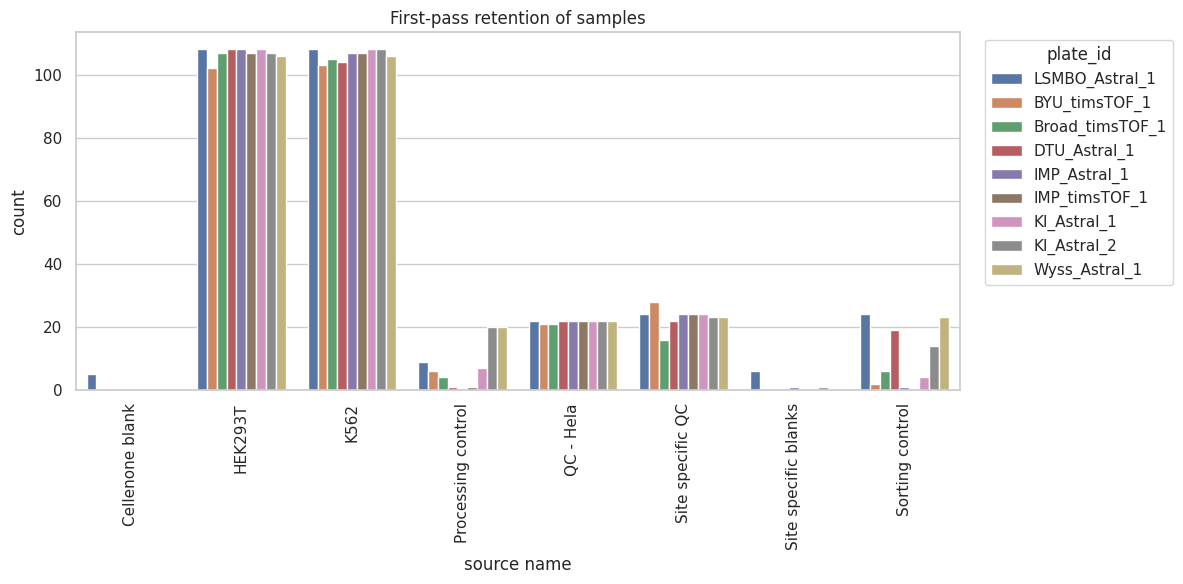

In [63]:
counts = adata_protein.obs.groupby(['source name', 'plate_id']).size().reset_index(name='count')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=counts, x='source name', y='count', hue='plate_id', dodge=True)
ax.set_xlabel('source name')
ax.set_ylabel('count')
plt.xticks(rotation=90)
plt.title('First-pass retention of samples')
plt.legend(title='plate_id', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Second pass
pd.DataFrame({
    name: {
        "Samples":    a.n_obs,
        "Unique features": a.n_vars,
        "Layers":   ", ".join(a.layers.keys()),
        "obs cols": a.obs.shape[1],
        "var cols": a.var.shape[1],
        "% missing": f"{(np.isnan(a.X)).mean() * 100:.1f}%",  # or np.isnan
    }
    for a, name in [
        (adata_precursor,    "precursor"),
        (adata_protein,      "protein"),
        (adata_precursor_qc, "precursor QC"),
        (adata_protein_qc,   "protein QC"),
    ]
}).T

,Samples,Unique features,Layers,obs cols,var cols,% missing
precursor,2587,56328,"Precursor.Normalised, Ms1.Area, Ms1.Normalised...",28,50,90.2%
protein,2587,6321,"PG.TopN, PG.Q.Value, PG.PEP, Global.PG.Q.Value...",28,4,76.9%
precursor QC,171,30231,X_log2,28,50,78.1%
protein QC,171,5805,X_log2,28,4,62.5%


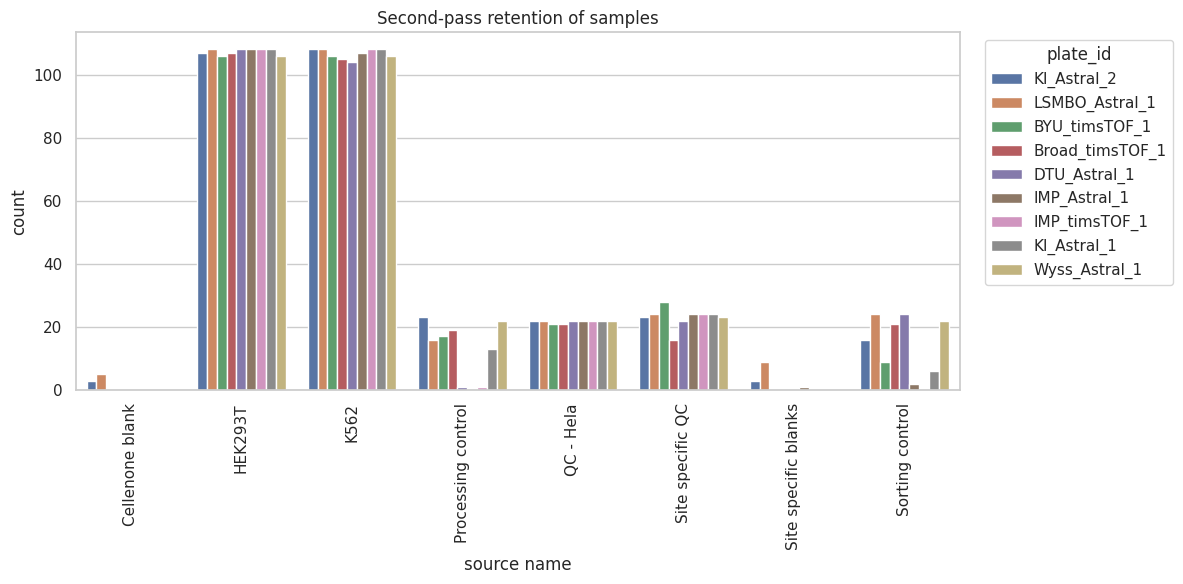

In [ ]:
counts = adata_protein.obs.groupby(['source name', 'plate_id']).size().reset_index(name='count')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=counts, x='source name', y='count', hue='plate_id', dodge=True)
ax.set_xlabel('source name')
ax.set_ylabel('count')
plt.xticks(rotation=90)
plt.title('Second-pass retention of samples')
plt.legend(title='plate_id', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 3. Save

Write all four AnnData objects to `Data/AnnData/` (`.h5ad` format) and the filtered long-format dataframes to `Data/Parquet/`. The parquet files preserve the full column set for any subsequent ad-hoc queries without needing to re-parse the raw Spectronaut TSVs.

> `convert_strings_to_categoricals=False` is set explicitly to avoid silent dtype changes that can break downstream string operations.

In [60]:
adata_precursor

AnnData object with n_obs × n_vars = 2495 × 63605
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes', 'Stripped.Sequence', 'Proteotypic', 'Modified.Sequence', 'Precursor.Charge', 'Precursor.Id', 'Precursor.Mz', 'Decoy', 'Q.Value', 'Global.Q.Value', 'Lib.Q.Value', 'PEP', 'Peptidoform.Q.Value', 'Global.Peptidoform.Q.Value', 'PG.Q.Value', 'PG.PEP', 'Global.PG.Q.Value', 'Protein.Q.Value', 'GG.Q.Value', 'Channe

In [ ]:
adata_precursor

AnnData object with n_obs × n_vars = 2587 × 56328
    obs: 'Run', 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type'
    var: 'Protein.Group', 'Protein.Ids', 'Protein.Names', 'Genes', 'Stripped.Sequence', 'Proteotypic', 'Modified.Sequence', 'Precursor.Charge', 'Precursor.Id', 'Precursor.Mz', 'Decoy', 'Q.Value', 'Global.Q.Value', 'Lib.Q.Value', 'PEP', 'Peptidoform.Q.Value', 'Global.Peptidoform.Q.Value', 'PG.Q.Value', 'PG.PEP', 'Global.PG.Q.Value', 'Protein.Q.Value', 'GG.Q.Value', 'Channe

In [73]:
ANNDATA_OUT = os.path.join(
    ROOT_OUT,
    'AnnData',
    'DIANN',
    # 'first_pass',
    'second_pass',
    'base'
)
Path(ANNDATA_OUT).mkdir(parents=True, exist_ok=True)

adata_precursor.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
    convert_strings_to_categoricals=False
)
adata_precursor_qc.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor_qc.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein_qc.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein_qc.h5ad'),
    convert_strings_to_categoricals=False
)
